# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import AIRPolSARSegDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import numpy as np

## Visualize images and masks

New train/val/test split

In [5]:
# all 4 bands 
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg",
    "csv_file": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/air_polsar_seg_train.csv",
    "selection": "all"
}
dataset = AIRPolSARSegDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 300


In [6]:
# user-defined bands
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg",
    "csv_file": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/air_polsar_seg_train.csv",
    "selection": "bands",
    "bands_gf3": ["VV"]
}
dataset = AIRPolSARSegDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 300


Original train/test split

Total number of patches: 350


2026-04-09 11:07:30,923 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


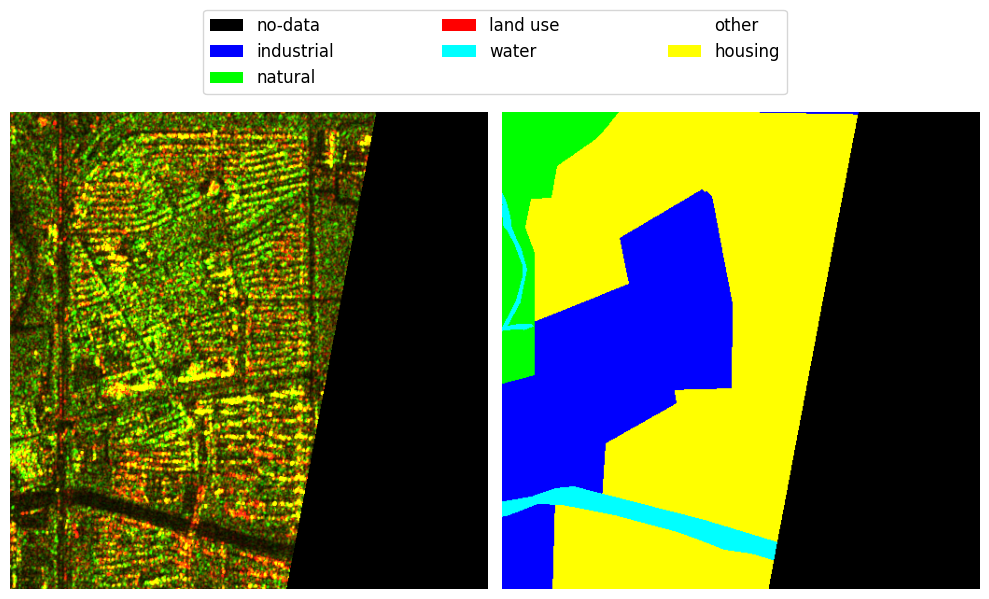

2026-04-09 11:07:35,477 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


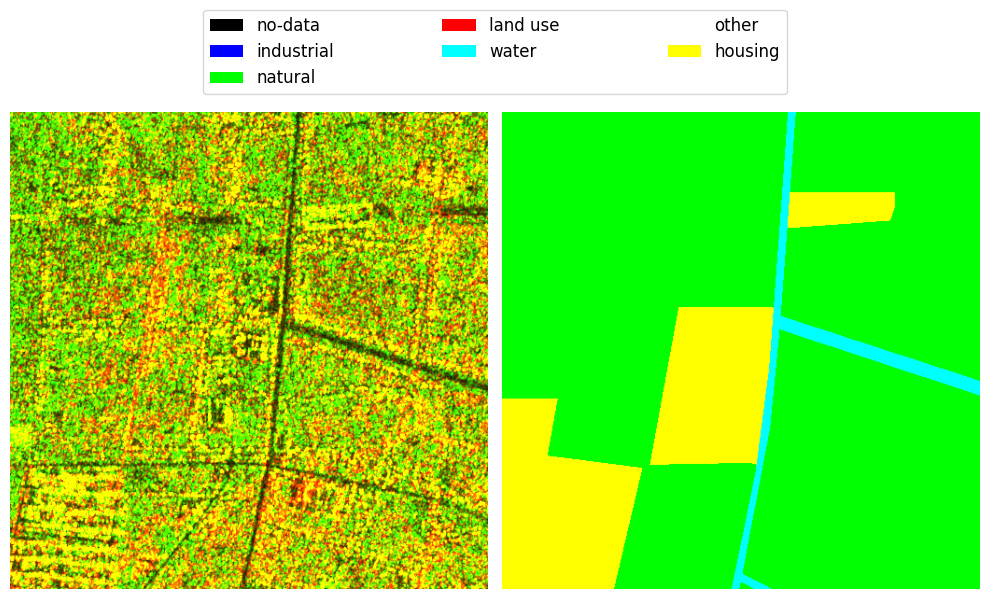

2026-04-09 11:07:39,959 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


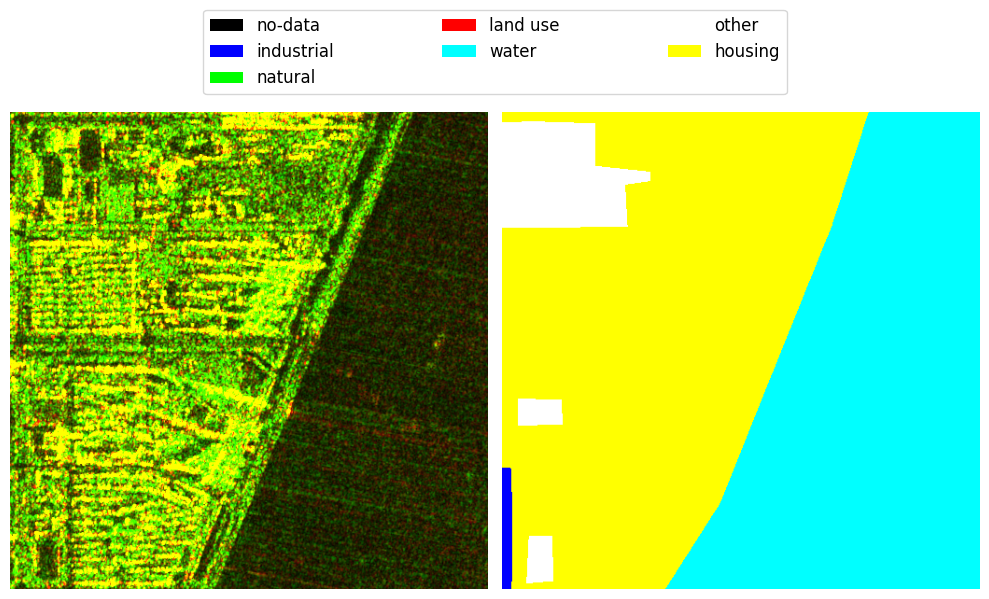

In [52]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/train_set/",
    "selection": "rgb"
}
dataset = AIRPolSARSegDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(100);

In [16]:
dataset.data_distribution_table()

,Number of pixels
industrial,31545016.0
natural,35568020.0
land use,1593888.0
water,10201878.0
other,2185057.0
housing,49978144.0


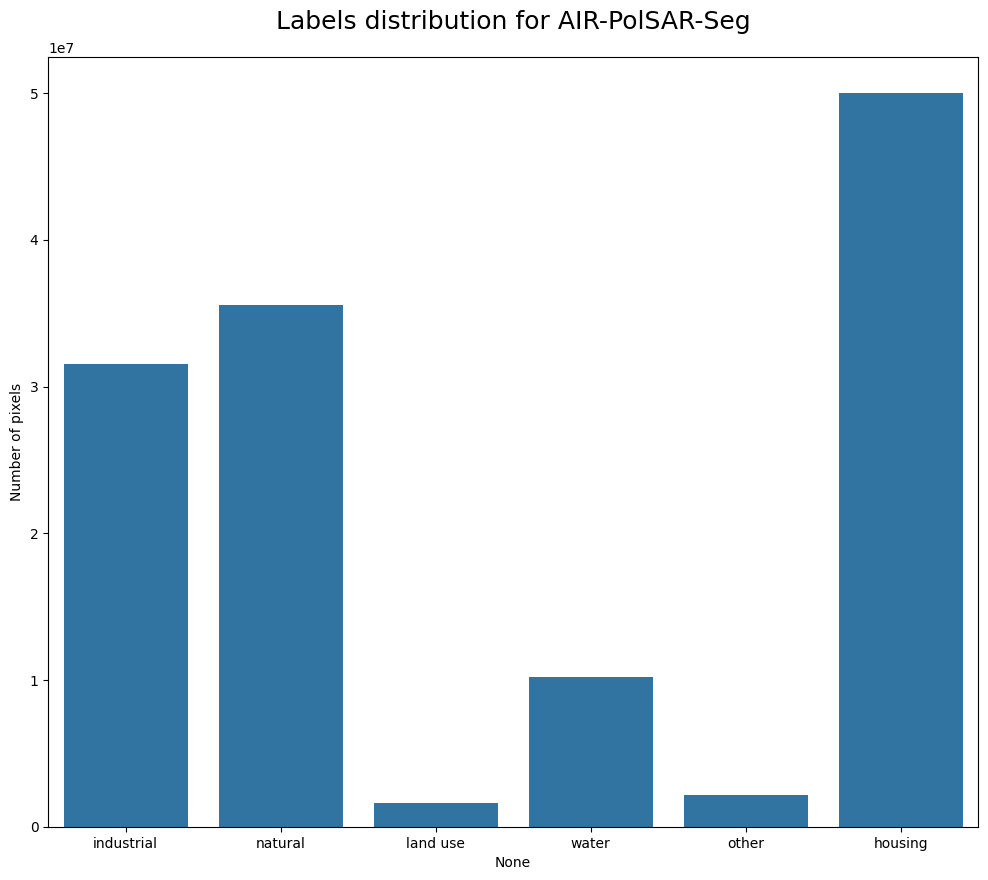

In [17]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/train_set",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = AIRPolSARSegDataset(train_dataset_config)
len(train_dataset)

350

## Create the model

In [40]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [8]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-21 08:27:38,432 INFO Starting training.
training: 100%|██████████| 35/35 [05:34<00:00,  9.56s/it]
2025-11-21 08:33:13,062 INFO epoch: 1, time: 335, loss:  0.69023
testing on train set: 100%|██████████| 35/35 [05:34<00:00,  9.56s/it]
2025-11-21 08:38:49,607 INFO IOU:0.3584194417653432, IOU mean:0.2516669676804966, IOU per Class:[0.39024525 0.45161251 0.01481436 0.19066745 0.03556975 0.42709247]
training: 100%|██████████| 35/35 [05:34<00:00,  9.56s/it]
2025-11-21 08:44:24,215 INFO epoch: 2, time: 335, loss:  0.60696
testing on train set: 100%|██████████| 35/35 [05:35<00:00,  9.58s/it]
2025-11-21 08:49:59,681 INFO IOU:0.5631944271495466, IOU mean:0.4228249511812374, IOU per Class:[0.58162957 0.53257762 0.02135288 0.61028013 0.19186914 0.59924037]
training: 100%|██████████| 35/35 [05:51<00:00, 10.04s/it]
2025-11-21 08:55:51,222 INFO epoch: 3, time: 352, loss:  0.55829
testing on train set: 100%|██████████| 35/35 [08:00<00:00, 13.74s/it]
2025-11-21 09:03:52,170 INFO IOU:0.6200503506

## Evaluate the model

In [9]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = AIRPolSARSegDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

150


2025-11-21 14:04:55,121 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar
2025-11-21 14:04:55,596 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 38/38 [02:30<00:00,  3.95s/it]


[{'IOU': 0.5661281770789414,
  'IOU mean': 0.5145827702451954,
  'IOU per Class': array([0.43610947, 0.61765784, 0.        , 0.75615742, 0.66176933,
         0.61580257])}]

## Predictions

2025-11-21 14:07:25,717 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar
2025-11-21 14:07:26,138 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar at epoch 11
2025-11-21 14:07:26,244 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-11-21 14:07:26,434 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-11-21 14:07:26,606 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


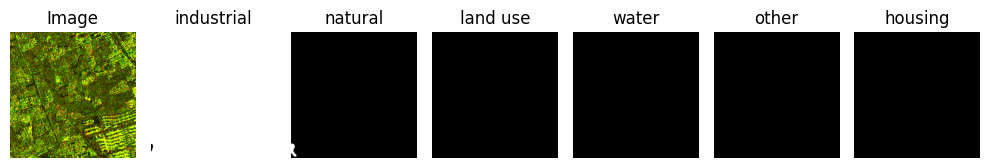

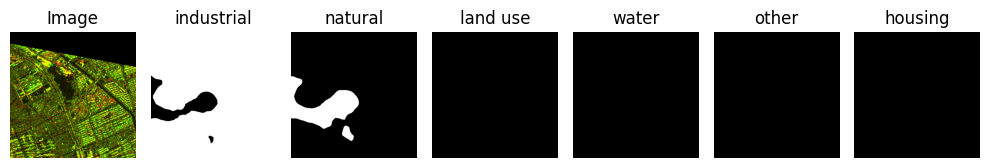

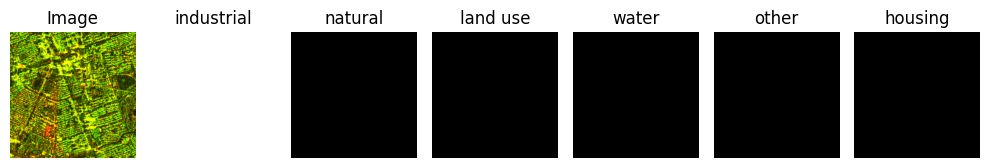

In [10]:
model_path = "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar"
labels = ["industrial","natural","land use","water","other","housing"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-2_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-2_HV.tiff')
image = np.dstack((imageHH, imageHV, (imageHH/imageHV).astype("uint16")))
fig = model.predict_masks(image, labels, transform)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-9_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-9_HV.tiff')
image = np.dstack((imageHH, imageHV, (imageHH/imageHV).astype("uint16")))
fig = model.predict_masks(image, labels, transform)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-65_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-65_HV.tiff')
image = np.dstack((imageHH, imageHV, (imageHH/imageHV).astype("uint16")))
fig = model.predict_masks(image, labels, transform)